# 04 — Utility Functions: Prototype, Test, Visualize

This notebook is a workbench for the utility functions that `app.py` and later analysis notebooks will import from `scripts/data_utils.py`. Each function is defined here, checked against a known fact so a bug can't sneak through quietly, and paired with a plot so the shape of its output is obvious.

**Workflow:** prototype and test a function in a section below, then once it's settled, move it into `scripts/data_utils.py` and replace the definition here with an import. Nothing is extracted yet — this notebook is the source of truth for now.

Functions prototyped here:
1. `load_matches` — load `clean_data/matches.csv` with the right dtypes
2. `to_team_matches` — reshape match-grain rows into team-grain rows, for filtering by a single team
3. `league_table` — standings for a season, built from `to_team_matches`
4. `team_form` — a team's rolling points and W/D/L sequence over a season
5. `head_to_head` — the all-time record between two teams

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

ROOT = Path.cwd() if (Path.cwd() / "clean_data").exists() else Path.cwd().parent
CLEAN_DATA = ROOT / "clean_data"
sys.path.append(str(ROOT / "scripts"))
from data_utils import load_matches, to_team_matches, league_table, team_form, head_to_head

# Colors from the project's validated palette (dataviz skill, references/palette.md)
BLUE, RED, GRAY = "#2a78d6", "#e34948", "#9a988f"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                      "grid.color": "#e5e4e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
                      "figure.facecolor": "white", "axes.facecolor": "white"})

## 1. `load_matches`

Loads `clean_data/matches.csv`, parses `date`, and orders columns and rows the same way every time. This is the single entry point every other function and notebook should use instead of reading the CSV directly.

In [2]:
# load_matches() now lives in scripts/data_utils.py — imported above
matches = load_matches()
print(f"shape: {matches.shape}  |  seasons: {matches['season'].min()}–{matches['season'].max()}")
matches.head()

shape: (13166, 13)  |  seasons: 1992-93–2025-26


,match_id,season,season_start_year,date,day_of_week,home_team,away_team,home_team_code,away_team_code,home_goals,away_goals,result,sources
0,1992-93_ARS_NOR,1992-93,1992,1992-08-15,Sat,Arsenal,Norwich City,ARS,NOR,2,4,A,epl-92-23
1,1992-93_CHE_OLD,1992-93,1992,1992-08-15,Sat,Chelsea,Oldham Athletic,CHE,OLD,1,1,D,epl-92-23
2,1992-93_COV_MID,1992-93,1992,1992-08-15,Sat,Coventry City,Middlesbrough,COV,MID,2,1,H,epl-92-23
3,1992-93_CRY_BLB,1992-93,1992,1992-08-15,Sat,Crystal Palace,Blackburn Rovers,CRY,BLB,3,3,D,epl-92-23
4,1992-93_EVE_SHW,1992-93,1992,1992-08-15,Sat,Everton,Sheffield Wednesday,EVE,SHW,1,1,D,epl-92-23


In [3]:
# Test: matches the inventory notebooks (01-03, 06): every season complete, 1992-93 to 2025-26
assert matches.shape == (13_166, 13)
assert matches["season"].nunique() == 34
assert matches["match_id"].is_unique
assert matches.isna().sum().sum() == 0
print("load_matches: OK")

load_matches: OK


## 2. `to_team_matches`

`matches.csv` is match-grain: one row per fixture, with separate `home_*`/`away_*` columns. Most analysis wants **team-grain**: one row per team per match, so you can filter to a single team with `team == "Arsenal"` instead of an `(home_team == X) | (away_team == X)` every time.

Each match becomes two rows — one from each side's perspective — with `venue`, goals for/against, and points already computed.

In [4]:
# to_team_matches() now lives in scripts/data_utils.py — imported above
team_matches = to_team_matches(matches)
print(f"shape: {team_matches.shape}  (2 × matches: {len(matches)} × 2 = {len(matches) * 2})")
team_matches.head()

shape: (26332, 15)  (2 × matches: 13166 × 2 = 26332)


,match_id,season,season_start_year,date,day_of_week,team,team_code,opponent,opponent_code,goals_for,goals_against,venue,outcome,goal_diff,points
0,1992-93_ARS_NOR,1992-93,1992,1992-08-15,Sat,Arsenal,ARS,Norwich City,NOR,2,4,Home,L,-2,0
1,1992-93_IPS_AVL,1992-93,1992,1992-08-15,Sat,Aston Villa,AVL,Ipswich Town,IPS,1,1,Away,D,0,1
2,1992-93_CRY_BLB,1992-93,1992,1992-08-15,Sat,Blackburn Rovers,BLB,Crystal Palace,CRY,3,3,Away,D,0,1
3,1992-93_CHE_OLD,1992-93,1992,1992-08-15,Sat,Chelsea,CHE,Oldham Athletic,OLD,1,1,Home,D,0,1
4,1992-93_COV_MID,1992-93,1992,1992-08-15,Sat,Coventry City,COV,Middlesbrough,MID,2,1,Home,W,1,3


In [5]:
# Tests: row count doubles, each match's two rows mirror each other, points total is sane
assert len(team_matches) == len(matches) * 2

pair = team_matches.merge(team_matches, on=["match_id", "opponent"], suffixes=("", "_opp"))
pair = pair[pair["team"] != pair["team_opp"]]
assert (pair["goals_for"] == pair["goals_against_opp"]).all(), "goals_for should mirror the opponent's goals_against"
assert (pair["points"] + pair["points_opp"]).isin([2, 3]).all(), "a match awards 2 points (draw) or 3 (win+loss)"

arsenal_outcomes = team_matches.query("team == 'Arsenal' and season == '2003-04'")["outcome"].value_counts().to_dict()
assert arsenal_outcomes == {"W": 26, "D": 12}, arsenal_outcomes
print("to_team_matches: OK")

to_team_matches: OK


Filtering by team is now a one-liner. As a sanity check, a single team's goals across a season:

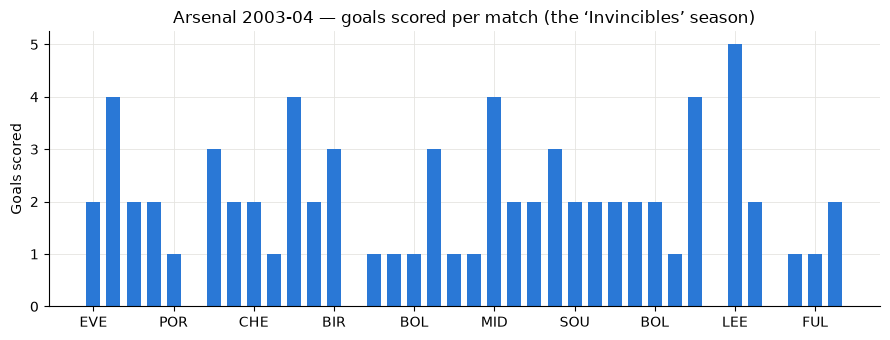

In [6]:
arsenal_0304 = team_matches.query("team == 'Arsenal' and season == '2003-04'").sort_values("date")

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(range(len(arsenal_0304)), arsenal_0304["goals_for"], color=BLUE, width=0.7)
ax.set_xticks(range(0, len(arsenal_0304), 4))
ax.set_xticklabels(arsenal_0304["opponent_code"].iloc[::4], rotation=0)
ax.set_ylabel("Goals scored")
ax.set_title("Arsenal 2003-04 — goals scored per match (the ‘Invincibles’ season)")
plt.tight_layout()
plt.show()

## 3. `league_table`

Standings for one season, built on top of `to_team_matches`. Ties are broken the Premier League way: points, then goal difference, then goals scored.

In [7]:
# league_table() now lives in scripts/data_utils.py — imported above
table_0304 = league_table(team_matches, "2003-04")
table_0304

,team,played,wins,draws,losses,goals_for,goals_against,points,goal_diff
position,,,,,,,,,
1,Arsenal,38,26,12,0,73,26,90,47
2,Chelsea,38,24,7,7,67,30,79,37
3,Manchester United,38,23,6,9,64,35,75,29
4,Liverpool,38,16,12,10,55,37,60,18
5,Newcastle United,38,13,17,8,52,40,56,12
6,Aston Villa,38,15,11,12,48,44,56,4
7,Charlton Athletic,38,14,11,13,51,51,53,0
8,Bolton Wanderers,38,14,11,13,48,56,53,-8
9,Fulham,38,14,10,14,52,46,52,6


In [8]:
# Test: the 2003-04 "Invincibles" season - Arsenal unbeaten, 90 points, no losses
top = table_0304.iloc[0]
assert top["team"] == "Arsenal"
assert top["points"] == 90
assert top["losses"] == 0
assert table_0304["played"].eq(38).all()
print("league_table: OK — Arsenal 2003-04: unbeaten, 90 pts")

league_table: OK — Arsenal 2003-04: unbeaten, 90 pts


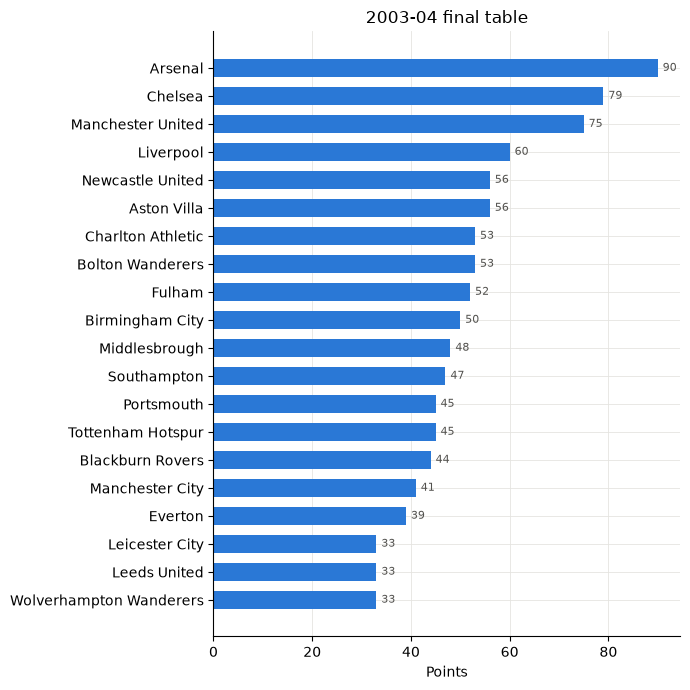

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
y = range(len(table_0304), 0, -1)
ax.barh(y, table_0304["points"], color=BLUE, height=0.65)
ax.set_yticks(y)
ax.set_yticklabels(table_0304["team"])
ax.set_xlabel("Points")
ax.set_title("2003-04 final table")
for yi, pts in zip(y, table_0304["points"]):
    ax.text(pts + 1, yi, str(pts), va="center", fontsize=8, color="#52514e")
plt.tight_layout()
plt.show()

## 4. `team_form`

A team's match-by-match record across a season: outcome, points, and a rolling points total over the last *n* matches (default 5) — the usual "form" window.

In [10]:
# team_form() now lives in scripts/data_utils.py — imported above
form = team_form(team_matches, "Arsenal", "2003-04")
form.head(10)

,matchday,date,opponent,venue,goals_for,goals_against,outcome,points,rolling_points,cumulative_points
0,1,2003-08-16,Everton,Home,2,1,W,3,3.0,3
1,2,2003-08-24,Middlesbrough,Away,4,0,W,3,6.0,6
2,3,2003-08-27,Aston Villa,Home,2,0,W,3,9.0,9
3,4,2003-08-31,Manchester City,Away,2,1,W,3,12.0,12
4,5,2003-09-13,Portsmouth,Home,1,1,D,1,13.0,13
5,6,2003-09-21,Manchester United,Away,0,0,D,1,11.0,14
6,7,2003-09-26,Newcastle United,Home,3,2,W,3,11.0,17
7,8,2003-10-04,Liverpool,Away,2,1,W,3,11.0,20
8,9,2003-10-18,Chelsea,Home,2,1,W,3,11.0,23
9,10,2003-10-26,Charlton Athletic,Away,1,1,D,1,11.0,24


In [11]:
# Test: cumulative points at the last matchday equals the league_table total; form string has 38 games
assert form["cumulative_points"].iloc[-1] == table_0304.set_index("team").loc["Arsenal", "points"]
assert len(form) == 38
assert form["outcome"].eq("L").sum() == 0
print("team_form: OK")

team_form: OK


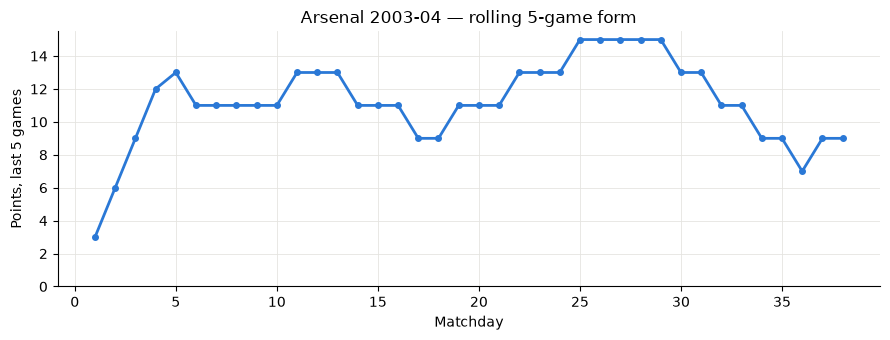

In [12]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(form["matchday"], form["rolling_points"], color=BLUE, linewidth=2, marker="o", markersize=4)
ax.set_xlabel("Matchday")
ax.set_ylabel("Points, last 5 games")
ax.set_ylim(0, 15.5)
ax.set_title("Arsenal 2003-04 — rolling 5-game form")
plt.tight_layout()
plt.show()

## 5. `head_to_head`

The all-time record between two teams, across every season both files cover, plus the match list.

In [13]:
# head_to_head() now lives in scripts/data_utils.py — imported above
h2h_summary, h2h_games = head_to_head(matches, "Arsenal", "Tottenham Hotspur")
h2h_summary

{'team_a': 'Arsenal',
 'team_b': 'Tottenham Hotspur',
 'played': 68,
 'Arsenal_wins': 29,
 'draws': 24,
 'Tottenham Hotspur_wins': 15}

In [14]:
# Test: the three counts add up to the number of matches played
assert h2h_summary["played"] == len(h2h_games)
assert h2h_summary["Arsenal_wins"] + h2h_summary["draws"] + h2h_summary["Tottenham Hotspur_wins"] == h2h_summary["played"]
print("head_to_head: OK")

head_to_head: OK


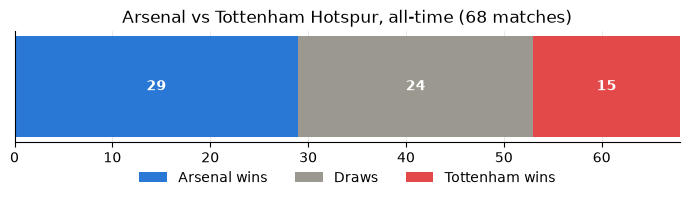

In [15]:
fig, ax = plt.subplots(figsize=(7, 2.2))
labels = ["Arsenal wins", "Draws", "Tottenham wins"]
values = [h2h_summary["Arsenal_wins"], h2h_summary["draws"], h2h_summary["Tottenham Hotspur_wins"]]
colors = [BLUE, GRAY, RED]
left = 0
for label, value, color in zip(labels, values, colors):
    ax.barh(0, value, left=left, color=color, height=0.55)
    if value > 0:
        ax.text(left + value / 2, 0, str(value), ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    left += value
ax.set_xlim(0, left)
ax.set_yticks([])
ax.legend(labels, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
ax.set_title(f"Arsenal vs Tottenham Hotspur, all-time ({h2h_summary['played']} matches)")
plt.tight_layout()
plt.show()

## 6. Next step

All five functions live in `scripts/data_utils.py` and pass their checks here. `app.py` and any notebook import them the same way this notebook does:

```python
import sys
sys.path.append(str(ROOT / "scripts"))
from data_utils import load_matches, to_team_matches, league_table, team_form, head_to_head
```

Candidates for the *next* round of utilities, once there's a concrete need: a multi-season league table (points-per-game, so seasons of different length compare fairly), a "current form" table across all teams for a season, and a squad-stats loader for `epl-25-26/team_season_stats.csv` once more of the 2025-26 season is downloaded.